# Annotated set: exploratory analysis

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager as fm

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE, ACCENT = "#e1e0d9", "#ffffff", "#c1121f"
NEUTRAL = MUTED

TEXTWIDTH = 15.0 / 2.54
FIGDIR = "figures"
FONT = "TeX Gyre Pagella"
IMG_W, IMG_H = 1920, 1080
QUINTILE_EDGES = [5, 7, 9, 12]

# The thesis is set in newpxtext; TeX Gyre Pagella is the same design.
FONT_DIR = "/usr/local/texlive/2023/texmf-dist/fonts/opentype/public/tex-gyre/"
for _s in ("regular", "bold", "italic", "bolditalic"):
    _p = os.path.join(FONT_DIR, f"texgyrepagella-{_s}.otf")
    if os.path.exists(_p):
        fm.fontManager.addfont(_p)

mpl.rcParams.update({
    "font.family": FONT if any(f.name == FONT for f in fm.fontManager.ttflist) else "serif",
    "font.size": 8.5, "axes.titlesize": 9, "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.edgecolor": INK2, "axes.linewidth": 0.6, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "savefig.bbox": "tight", "savefig.pad_inches": 0.01,
})

def hgrid(ax):
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=0.5)
    ax.grid(axis="x", visible=False)

def save(fig, name):
    os.makedirs(FIGDIR, exist_ok=True)
    fig.savefig(os.path.join(FIGDIR, name + ".pdf"))

In [2]:
lab = pd.read_csv("labels_contents.csv")
plan = json.load(open("plan_v2.json"))
counts = lab.groupby("filename").size()
pd.Series({"images": counts.size, "boxes": len(lab), "classes": lab["class"].nunique(),
           "mean": counts.mean(), "sd": counts.std(), "median": counts.median(),
           "min": counts.min(), "max": counts.max()})

images      1996.000000
boxes      17613.000000
classes        1.000000
mean           8.824148
sd             4.750480
median         8.000000
min            1.000000
max           29.000000
dtype: float64

## Density strata

In [3]:
cuts = [int(np.quantile(counts, q)) for q in (.2, .4, .6, .8)]
strata = pd.cut(counts, [-np.inf] + cuts + [np.inf], right=False,
                labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
pd.DataFrame({"images": strata.value_counts().sort_index(),
              "min": counts.groupby(strata, observed=True).min(),
              "max": counts.groupby(strata, observed=True).max()}).assign(edges=str(cuts))

,images,min,max,edges
Q1,337,1,4,"[5, 7, 9, 12]"
Q2,432,5,6,"[5, 7, 9, 12]"
Q3,370,7,8,"[5, 7, 9, 12]"
Q4,382,9,11,"[5, 7, 9, 12]"
Q5,475,12,29,"[5, 7, 9, 12]"


## Box geometry and the template filters

In [4]:
w_px, h_px = lab["w"] * IMG_W, lab["h"] * IMG_H
ratio_px = h_px / w_px
ratio_norm = lab["h"] / lab["w"]
area_px = w_px * h_px

geom_ok = ratio_px.between(0.6, 1.4)
area_ok = area_px >= area_px.mean() / 3
both_ok = geom_ok & area_ok

pd.Series({
    "median w (px)": w_px.median(), "median h (px)": h_px.median(),
    "median ratio (px frame)": ratio_px.median(),
    "median ratio (normalized)": ratio_norm.median(),
    "ratio inflation 1920/1080": IMG_W / IMG_H,
    "pass geometry %": 100 * geom_ok.mean(),
    "pass area %": 100 * area_ok.mean(),
    "pass both %": 100 * both_ok.mean()})

median w (px)                215.036160
median h (px)                205.965720
median ratio (px frame)        0.968750
median ratio (normalized)      1.722222
ratio inflation 1920/1080      1.777778
pass geometry %               79.140408
pass area %                   87.611423
pass both %                   73.820474
dtype: float64

In [5]:
pd.DataFrame({"w_px": w_px, "h_px": h_px, "ratio_px": ratio_px,
              "w_resized_256": lab["w"] * 256, "h_resized_256": lab["h"] * 256}
            ).describe(percentiles=[.25, .5, .75]).T

,count,mean,std,min,25%,50%,75%,max
w_px,17613.0,227.653913,85.843490,0.000000,168.247680,215.036160,288.000000,604.801920
h_px,17613.0,215.355407,84.255398,5.400000,158.130360,205.965720,267.428520,709.200360
ratio_px,17613.0,inf,NaN,0.135679,0.790470,0.968750,1.133107,inf
w_resized_256,17613.0,30.353855,11.445799,0.000000,22.433024,28.671488,38.400000,80.640256
h_resized_256,17613.0,51.047208,19.971650,1.280000,37.482752,48.821504,63.390464,168.106752


## Partition

In [6]:
ids = counts.rename(lambda s: s[:-4] if s.endswith(".txt") else s)
sets = {k: plan[k] for k in ("template_set", "eval_set", "test_set")}
pd.DataFrame({"n": {k: len(v) for k, v in sets.items()},
              "mean_count": {k: ids.reindex(v).fillna(0).mean() for k, v in sets.items()},
              "overlap_with_others": {
                  k: len(set(v) & set().union(*[set(w) for j, w in sets.items() if j != k]))
                  for k, v in sets.items()}})

,n,mean_count,overlap_with_others
template_set,499,8.825651,0
eval_set,759,8.835310,0
test_set,738,8.811653,0


## Figures

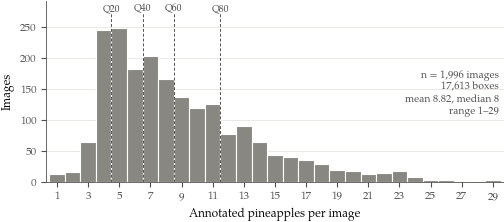

In [7]:
fig, ax = plt.subplots(figsize=(TEXTWIDTH, 2.35))
bins = np.arange(0.5, counts.max() + 1.5, 1)
ax.hist(counts, bins=bins, color=NEUTRAL, edgecolor="white", linewidth=0.8)

top = ax.get_ylim()[1] * 1.12
ax.set_ylim(0, top)
for q, name in zip(QUINTILE_EDGES, ["Q20", "Q40", "Q60", "Q80"]):
    ax.axvline(q - 0.5, color=INK2, lw=0.7, ls=(0, (3, 2)), ymax=0.93)
    ax.text(q - 0.5, top * 0.985, name, fontsize=7, color=INK2, va="top", ha="center")

ax.set_xlabel("Annotated pineapples per image")
ax.set_ylabel("Images")
ax.set_xticks(range(1, counts.max() + 1, 2))
ax.set_xlim(0.3, counts.max() + 0.7)
hgrid(ax)
ax.text(0.99, 0.62,
        f"n = {counts.size:,} images\n{len(lab):,} boxes\n"
        f"mean {counts.mean():.2f}, median {counts.median():.0f}\n"
        f"range {counts.min()}\u2013{counts.max()}",
        transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color=INK2)
save(fig, "eda_count_distribution")
plt.show()

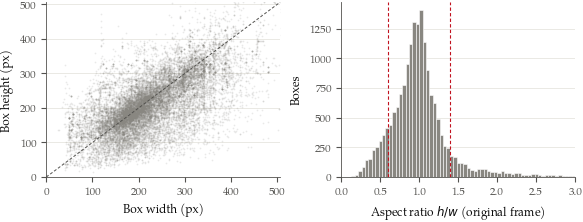

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(TEXTWIDTH, 2.3))

ax = axes[0]
ax.scatter(w_px, h_px, s=1.5, color=NEUTRAL, alpha=0.18, linewidths=0)
lim = [0, max(w_px.quantile(.995), h_px.quantile(.995))]
ax.plot(lim, lim, color=INK2, lw=0.7, ls=(0, (3, 2)))
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Box width (px)"); ax.set_ylabel("Box height (px)")
hgrid(ax)

ax = axes[1]
ax.hist(ratio_px, bins=np.linspace(0, 3, 70), color=NEUTRAL, edgecolor="white", linewidth=0.4)
for x in (0.6, 1.4):
    ax.axvline(x, color=ACCENT, lw=0.8, ls=(0, (3, 2)))
ax.set_xlabel("Aspect ratio $h/w$ (original frame)"); ax.set_ylabel("Boxes")
ax.set_xlim(0, 3)
hgrid(ax)
fig.tight_layout(pad=0.4)
save(fig, "eda_box_geometry")
plt.show()